In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow

Tue Oct 27 22:13:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("behavior-cheating").project("exam_cheating-keaor")
version = project.version(2)
dataset = version.download("yolov11")

print(dataset.location)
!cat {dataset.location}/data.yaml

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to exam_cheating-2 in yolov11:: 100%|██████████| 1549/1549 [00:00<00:00, 6468.99it/s]


/content/exam_cheating-2
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 4
names: ['Cheat_paper', 'Look_around', 'Normal', 'Use_phone']

roboflow:
  workspace: behavior-cheating
  project: exam_cheating-keaor
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/behavior-cheating/exam_cheating-keaor/dataset/2

In [3]:
import os, glob, yaml
from collections import Counter

root = "/content/exam_cheating-2"
cfg = yaml.safe_load(open(f"{root}/data.yaml"))
names = cfg["names"]

cfg["train"] = f"{root}/train/images"
cfg["val"] = f"{root}/valid/images"
cfg["test"] = f"{root}/test/images"
with open(f"{root}/data.yaml", "w") as f:
    yaml.safe_dump(cfg, f)

for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    counts = Counter()
    for lbl in glob.glob(f"{root}/{split}/labels/*.txt"):
        for line in open(lbl):
            parts = line.split()
            if parts:
                counts[names[int(parts[0])]] += 1
    print(f"{split:5} | images: {len(imgs):4} | {dict(counts)}")

def video_ids(split):
    ids = set()
    for p in glob.glob(f"{root}/{split}/images/*"):
        n = os.path.basename(p)
        if "_mp4" in n:
            ids.add(n.split("_mp4")[0])
    return ids

tr, va, te = video_ids("train"), video_ids("valid"), video_ids("test")
print("\nvideos in train:", len(tr), "| valid:", len(va), "| test:", len(te))
print("shared train & valid:", tr & va)
print("shared train & test:", tr & te)

train | images:  679 | {'Use_phone': 159, 'Look_around': 461, 'Cheat_paper': 108, 'Normal': 473}
valid | images:   63 | {'Look_around': 39, 'Normal': 66, 'Cheat_paper': 3, 'Use_phone': 4}
test  | images:   30 | {'Use_phone': 3, 'Look_around': 15, 'Normal': 32, 'Cheat_paper': 1}

videos in train: 3 | valid: 0 | test: 0
shared train & valid: set()
shared train & test: set()


In [5]:
import os, glob, random, shutil, yaml
from collections import Counter

random.seed(42)
SRC = "/content/exam_cheating-2"
DST = "/content/ds"
shutil.rmtree(DST, ignore_errors=True)
names = yaml.safe_load(open(f"{SRC}/data.yaml"))["names"]

items = []
for split in ["train", "valid", "test"]:
    for img in glob.glob(f"{SRC}/{split}/images/*"):
        base = os.path.splitext(os.path.basename(img))[0]
        lbl = f"{SRC}/{split}/labels/{base}.txt"
        cnt = Counter()
        if os.path.exists(lbl):
            for line in open(lbl):
                p = line.split()
                if p:
                    cnt[int(p[0])] += 1
        items.append({"img": img, "lbl": lbl, "cnt": cnt,
                      "video": "_mp4" in os.path.basename(img)})

videos = [it for it in items if it["video"]]
others = [it for it in items if not it["video"]]

pool = Counter()
for it in others:
    pool.update(it["cnt"])
FRAC = {"valid": 0.15, "test": 0.10}
need = {s: {c: FRAC[s] * pool[c] for c in pool} for s in FRAC}

random.shuffle(others)
others.sort(key=lambda it: min((pool[c] for c in it["cnt"]), default=10**9))

assign = {"train": list(videos), "valid": [], "test": []}
for it in others:
    best, best_gain = "train", 0
    for s in FRAC:
        if it["cnt"] and all(need[s][c] > 0 for c in it["cnt"]):
            gain = sum(need[s][c] for c in it["cnt"])
            if gain > best_gain:
                best, best_gain = s, gain
    assign[best].append(it)
    if best != "train":
        for c, n in it["cnt"].items():
            need[best][c] -= n

for s, lst in assign.items():
    os.makedirs(f"{DST}/{s}/images", exist_ok=True)
    os.makedirs(f"{DST}/{s}/labels", exist_ok=True)
    for it in lst:
        shutil.copy(it["img"], f"{DST}/{s}/images/")
        if os.path.exists(it["lbl"]):
            shutil.copy(it["lbl"], f"{DST}/{s}/labels/")

cfg = {"path": DST, "train": "train/images", "val": "valid/images",
       "test": "test/images", "nc": len(names), "names": names}
with open(f"{DST}/data.yaml", "w") as f:
    yaml.safe_dump(cfg, f)

for s, lst in assign.items():
    c = Counter()
    for it in lst:
        c.update(it["cnt"])
    print(f"{s:5} | images: {len(lst):4} |", {names[k]: v for k, v in sorted(c.items())})

train | images:  581 | {'Cheat_paper': 83, 'Look_around': 386, 'Normal': 425, 'Use_phone': 120}
valid | images:  103 | {'Cheat_paper': 17, 'Look_around': 77, 'Normal': 88, 'Use_phone': 25}
test  | images:   88 | {'Cheat_paper': 12, 'Look_around': 52, 'Normal': 58, 'Use_phone': 21}


In [6]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")
results = model.train(
    data="/content/ds/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    seed=42,
    project="/content/runs",
    name="baseline_yolo11s",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ds/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

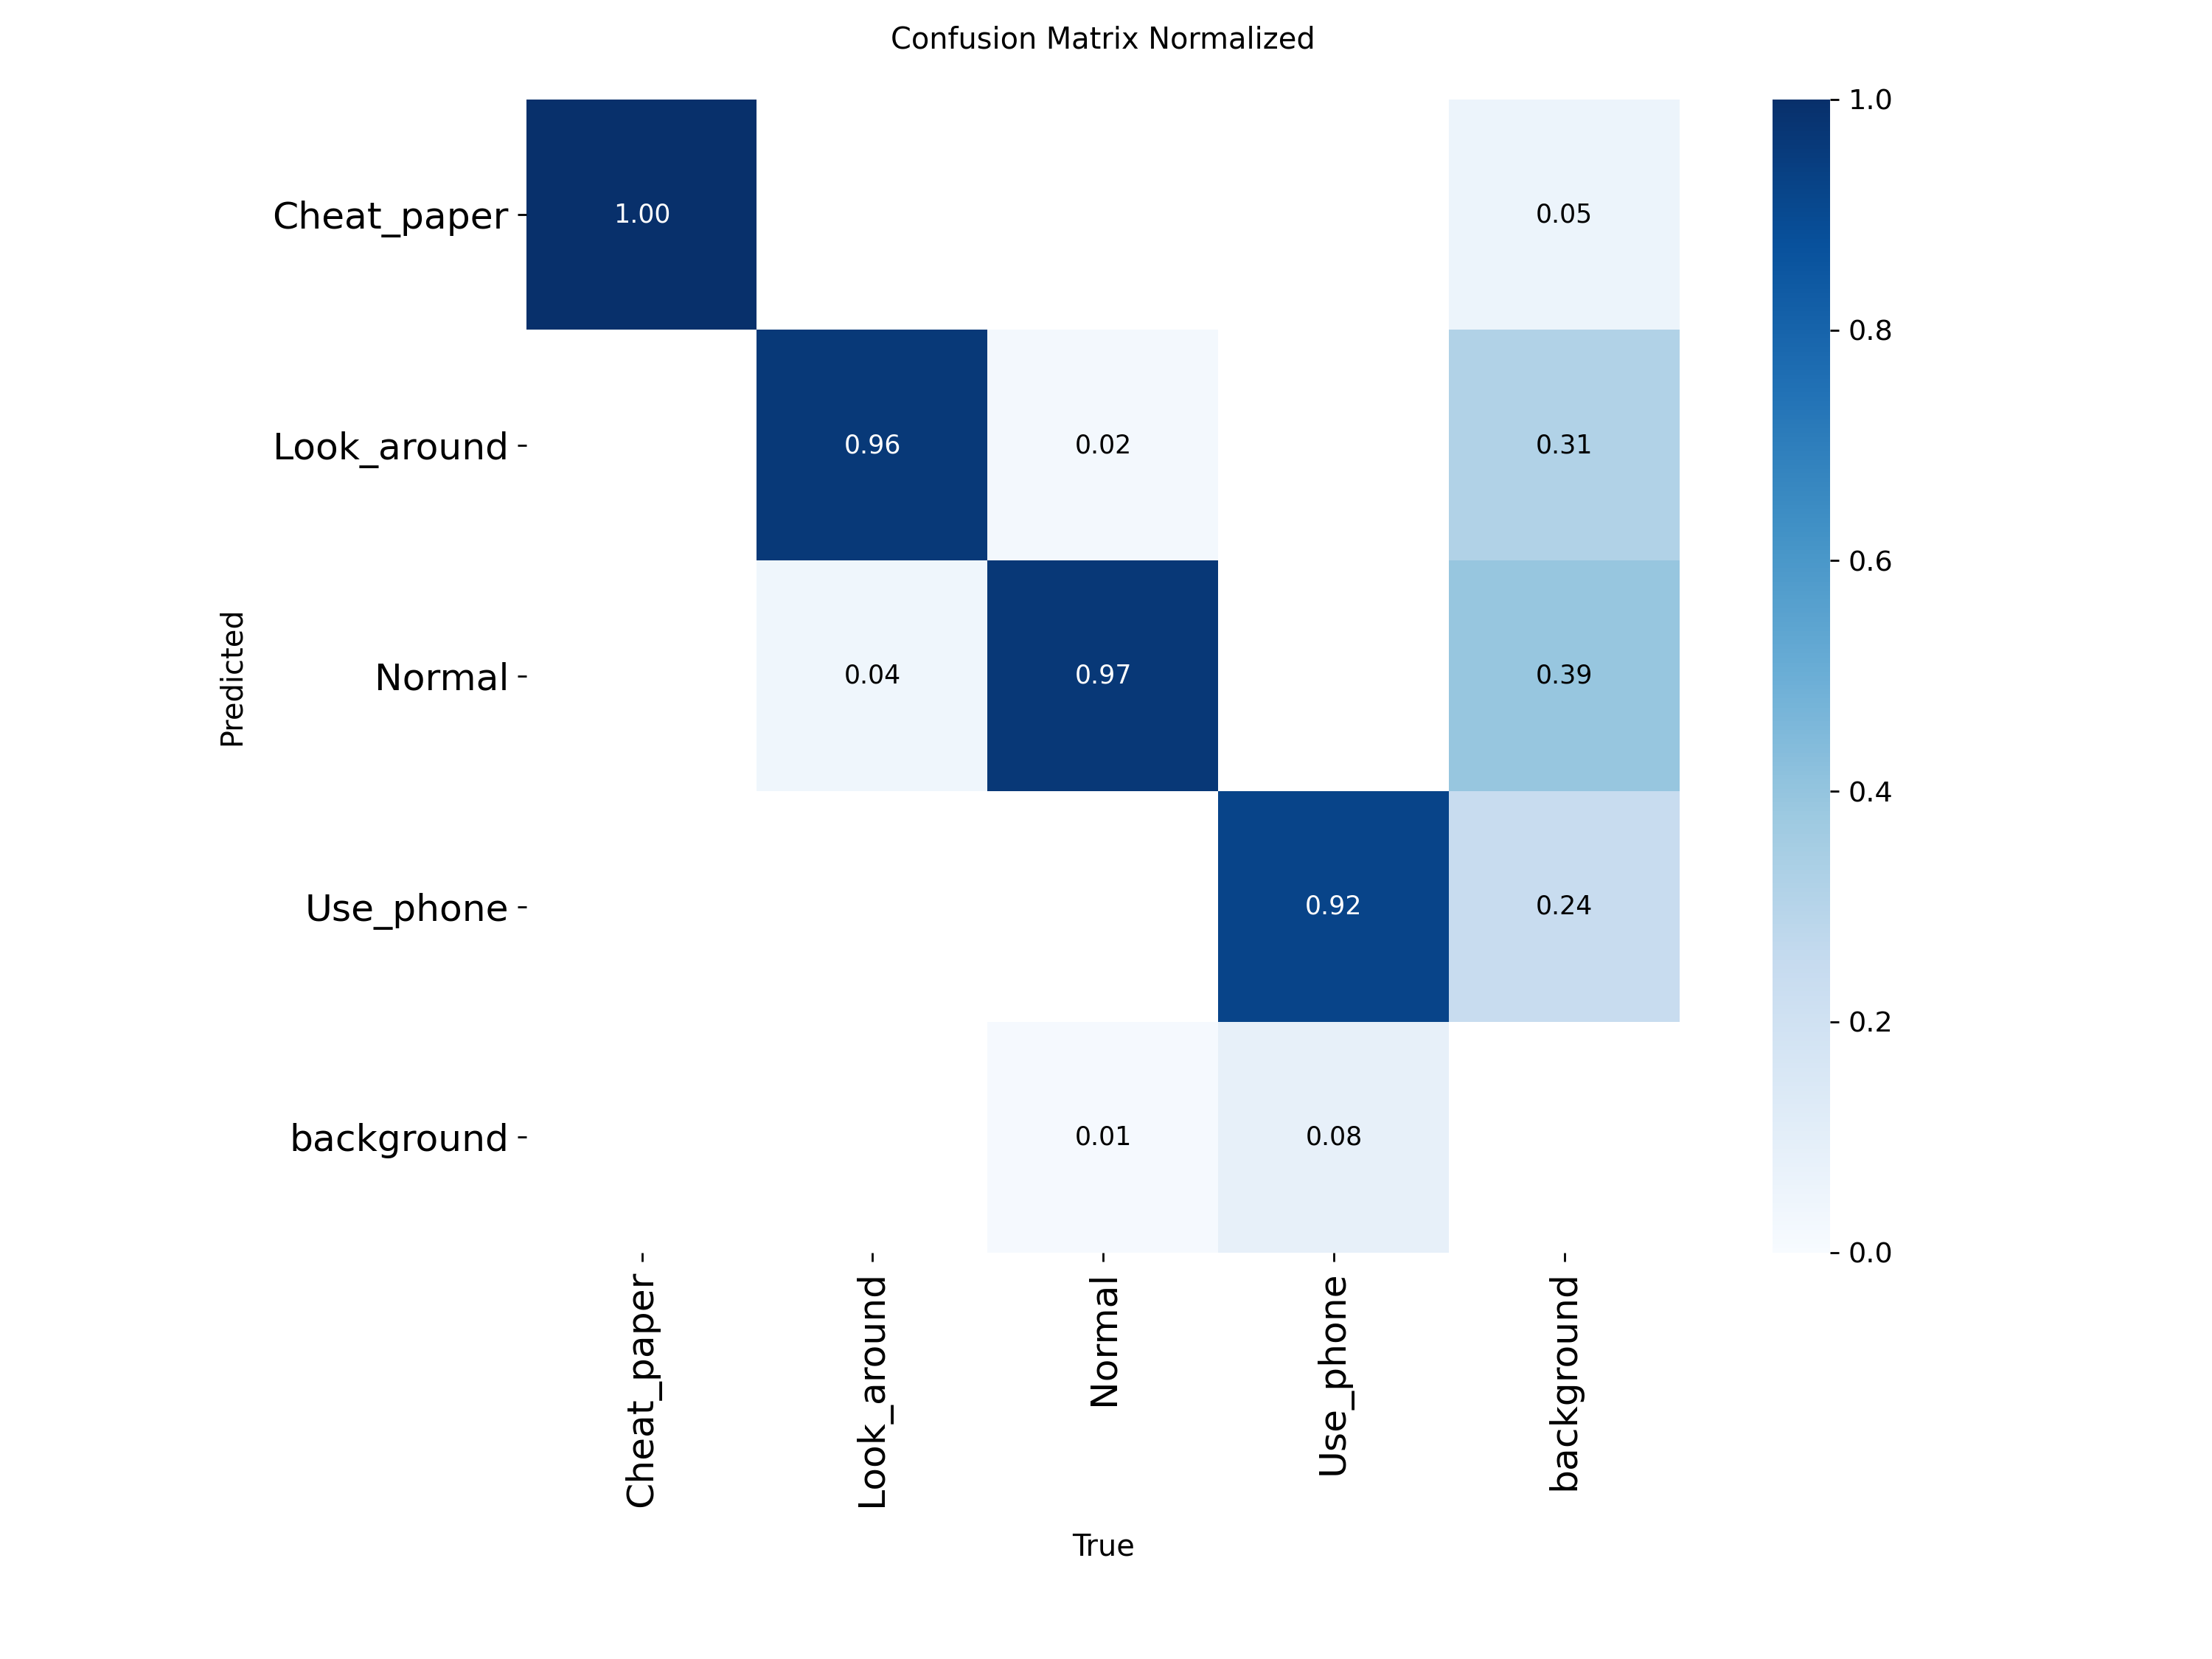

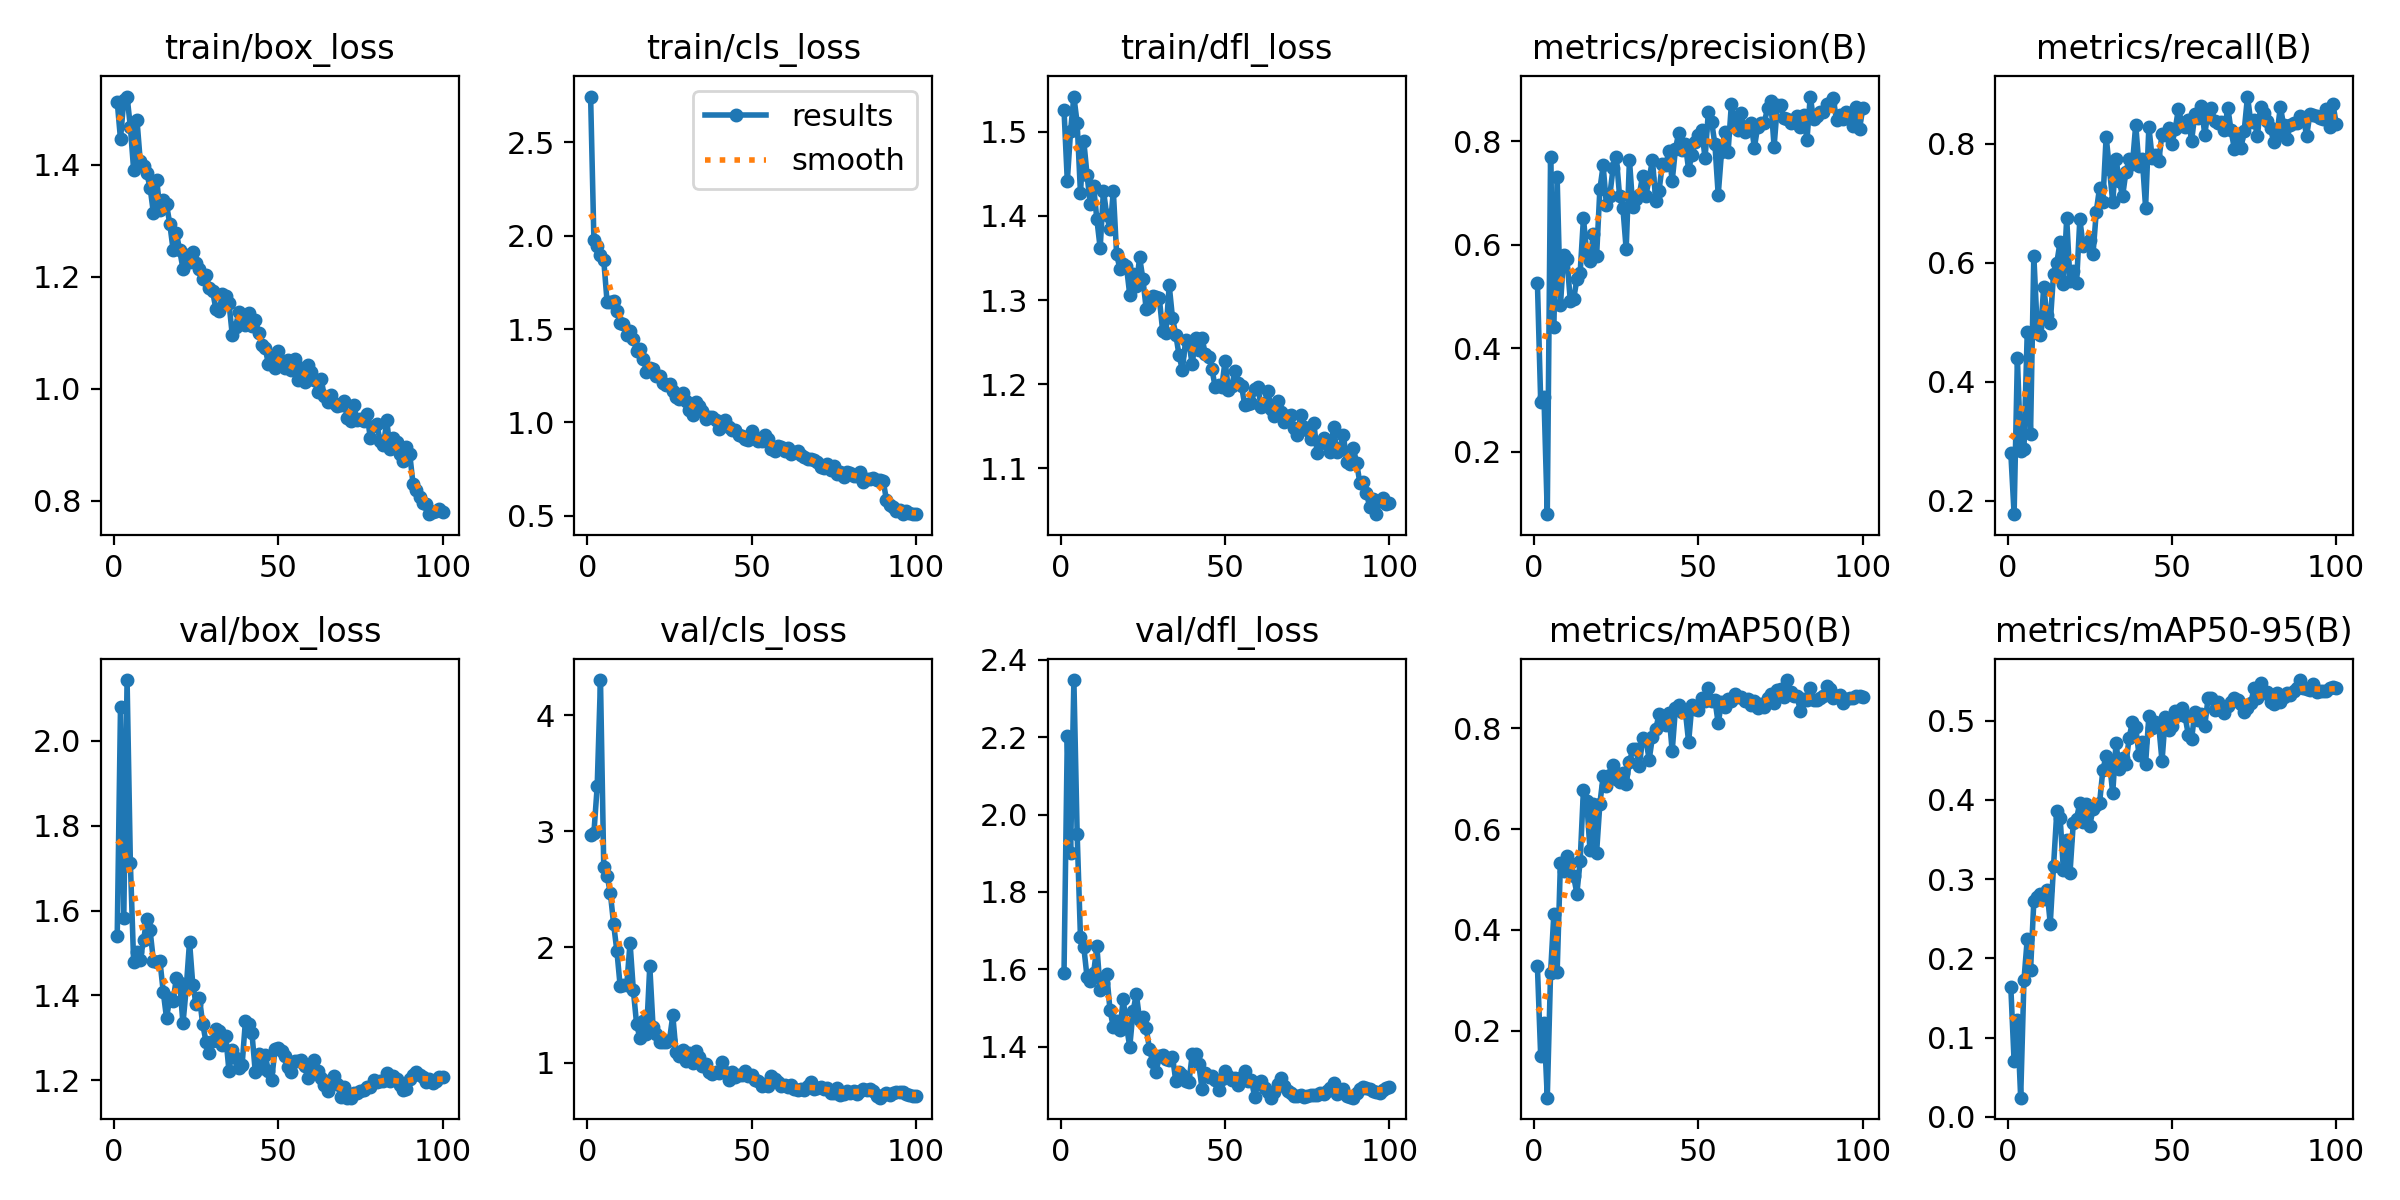

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from IPython.display import Image, display
from google.colab import files

d = "/content/runs/baseline_yolo11s"
display(Image(f"{d}/confusion_matrix_normalized.png"))
display(Image(f"{d}/results.png"))

files.download(f"{d}/weights/best.pt")